In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.16.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATA_DIR = Path(
    "/Users/manyamoonat/pbl sem5/Euphorbia_Augmented_3000"
)

print("Dataset exists:", DATA_DIR.exists())
print("Dataset path:", DATA_DIR)

for item in sorted(DATA_DIR.iterdir()):
    if item.is_dir():
        print(item.name, "->", len(list(item.iterdir())), "items")

Dataset exists: True
Dataset path: /Users/manyamoonat/pbl sem5/Euphorbia_Augmented_3000
.ipynb_checkpoints -> 1 items
diseased -> 1261 items
healthy -> 1951 items


In [3]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

tf.keras.utils.set_random_seed(SEED)

split_dirs = {
    name: DATA_DIR / name
    for name in ["train", "val", "test"]
}

has_splits = all(path.is_dir() for path in split_dirs.values())

if has_splits:
    train_ds = tf.keras.utils.image_dataset_from_directory(
        split_dirs["train"],
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        shuffle=True,
        seed=SEED
    )

    class_names = train_ds.class_names

    val_ds = tf.keras.utils.image_dataset_from_directory(
        split_dirs["val"],
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        class_names=class_names,
        shuffle=False
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        split_dirs["test"],
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        class_names=class_names,
        shuffle=False
    )

else:
    # Use only when the class folders contain independent examples
    # suitable for a random split. See the leakage warning below.
    all_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        validation_split=0.30,
        subset="training",
        seed=SEED,
        shuffle=True
    )

    val_test_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="binary",
        validation_split=0.30,
        subset="validation",
        seed=SEED,
        shuffle=True
    )

    class_names = all_ds.class_names

    val_batches = tf.data.experimental.cardinality(val_test_ds).numpy()
    test_batches = max(1, int(val_batches * 0.5))

    val_ds = val_test_ds.take(val_batches - test_batches)
    test_ds = val_test_ds.skip(val_batches - test_batches)

print("Classes:", class_names)

Found 3214 files belonging to 2 classes.
Using 2250 files for training.


2026-10-23 09:41:44.793459: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-23 09:41:44.793494: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-23 09:41:44.793497: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-23 09:41:44.793534: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-23 09:41:44.793559: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 3214 files belonging to 2 classes.
Using 964 files for validation.
Classes: ['diseased', 'healthy']


In [5]:
from pathlib import Path

DATA_DIR = Path(
    "/Users/manyamoonat/pbl sem5/Euphorbia_Augmented_3000"
)

for class_folder in sorted(DATA_DIR.iterdir()):
    if class_folder.is_dir():
        images = [
            f for f in class_folder.iterdir()
            if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        ]
        print(f"{class_folder.name}: {len(images)} images")

.ipynb_checkpoints: 0 images
diseased: 1260 images
healthy: 1950 images


In [6]:
from pathlib import Path

ORIGINAL_DIR = Path("/Users/manyamoonat/pbl sem5/Euphorbia_JPEG")

for folder in sorted(ORIGINAL_DIR.iterdir()):
    if folder.is_dir():
        images = [
            p for p in folder.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        ]
        print(folder.name, len(images))

diseased 126
healthy 195


In [7]:
import random
import shutil
from pathlib import Path

random.seed(42)

SPLIT_DIR = Path("/Users/manyamoonat/pbl sem5/Euphorbia_Clean_Split")

if SPLIT_DIR.exists():
    raise FileExistsError(
        f"{SPLIT_DIR} already exists. Rename it or choose another output path."
    )

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_dir in ORIGINAL_DIR.iterdir():
    if not class_dir.is_dir():
        continue

    images = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]
    random.shuffle(images)

    n = len(images)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    partitions = {
        "train": images[:n_train],
        "val": images[n_train:n_train + n_val],
        "test": images[n_train + n_val:]
    }

    for split, files in partitions.items():
        destination = SPLIT_DIR / split / class_dir.name
        destination.mkdir(parents=True, exist_ok=True)

        for src in files:
            shutil.copy2(src, destination / src.name)

        print(f"{split}/{class_dir.name}: {len(files)} images")

print("Clean split created at:", SPLIT_DIR)

train/diseased: 88 images
val/diseased: 18 images
test/diseased: 20 images
train/healthy: 136 images
val/healthy: 29 images
test/healthy: 30 images
Clean split created at: /Users/manyamoonat/pbl sem5/Euphorbia_Clean_Split


In [8]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED
)

class_names = train_ds.class_names

val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=class_names,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=class_names,
    shuffle=False
)

print("Classes:", class_names)

Found 224 files belonging to 2 classes.
Found 47 files belonging to 2 classes.
Found 50 files belonging to 2 classes.
Classes: ['diseased', 'healthy']


In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def prepare_dataset(ds, training=False):
    ds = ds.map(
        lambda images, labels: (
            tf.cast(images, tf.float32) / 255.0,
            labels
        ),
        num_parallel_calls=AUTOTUNE
    )

    if training:
        ds = ds.shuffle(500, seed=SEED)

    return ds.prefetch(AUTOTUNE)

train_ds = prepare_dataset(train_ds, training=True)
val_ds = prepare_dataset(val_ds)
test_ds = prepare_dataset(test_ds)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (128, 128)
Batch size: 16


In [10]:
from tensorflow.keras import layers, models, regularizers

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Data augmentation applied only during training
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),

    # CNN block 1
    layers.Conv2D(
        32, 3, padding="same",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.20),

    # CNN block 2
    layers.Conv2D(
        64, 3, padding="same",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    # CNN block 3
    layers.Conv2D(
        128, 3, padding="same",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
OUTPUT_DIR = Path("custom_cnn_results")
OUTPUT_DIR.mkdir(exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        OUTPUT_DIR / "best_custom_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30


2026-10-23 09:45:05.197011: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5752 - loss: 0.8823 - precision: 0.6357 - recall: 0.6632
Epoch 1: val_loss improved from None to 0.82439, saving model to custom_cnn_results/best_custom_cnn.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 112ms/step - accuracy: 0.5625 - loss: 0.9316 - precision: 0.6234 - recall: 0.7059 - val_accuracy: 0.4894 - val_loss: 0.8244 - val_precision: 0.5926 - val_recall: 0.5517 - learning_rate: 0.0010
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5783 - loss: 0.8764 - precision: 0.6484 - recall: 0.6874
Epoch 2: val_loss did not improve from 0.82439
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - accuracy: 0.5491 - loss: 0.9391 - precision: 0.6259 - recall: 0.6397 - val_accuracy: 0.3830 - val_loss: 0.8389 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6329 - loss: 0.8452 - precision: 0.6910 - recall: 0.7948
Epoch 3: val_loss did not improve from 

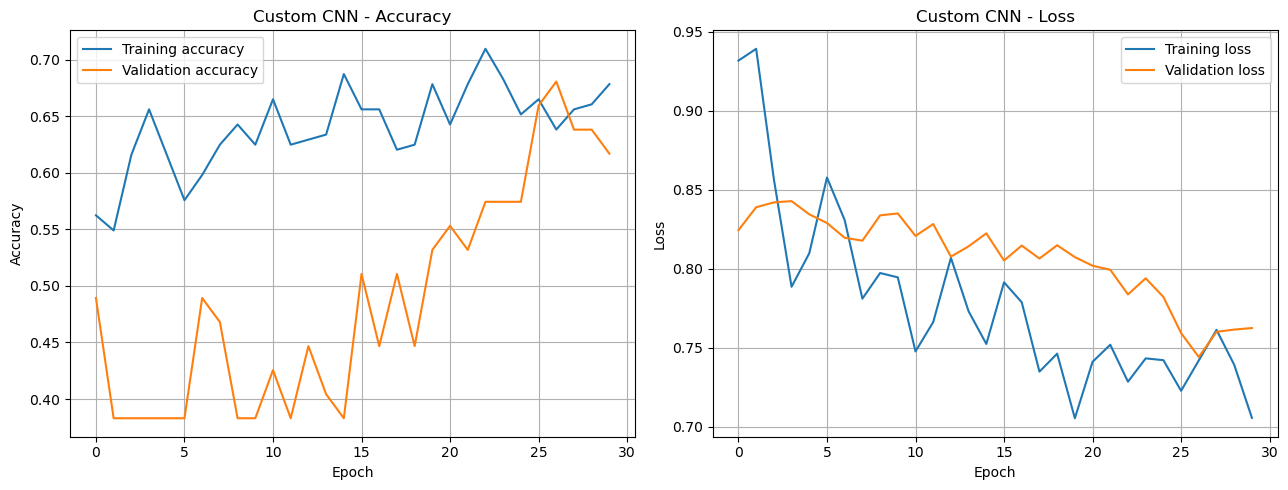

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Custom CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Custom CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=300)
plt.show()

In [13]:
best_model = tf.keras.models.load_model(
    OUTPUT_DIR / "best_custom_cnn.keras"
)

test_results = best_model.evaluate(test_ds, return_dict=True)

print("\nTest metrics:")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 187ms/step - accuracy: 0.5600 - loss: 0.7825 - precision: 0.7222 - recall: 0.4333        

Test metrics:
accuracy: 0.5600
loss: 0.7825
precision: 0.7222
recall: 0.4333


2026-10-23 09:47:28.118785: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step 

Classification Report:
              precision    recall  f1-score   support

    diseased     0.4688    0.7500    0.5769        20
     healthy     0.7222    0.4333    0.5417        30

    accuracy                         0.5600        50
   macro avg     0.5955    0.5917    0.5593        50
weighted avg     0.6208    0.5600    0.5558        50



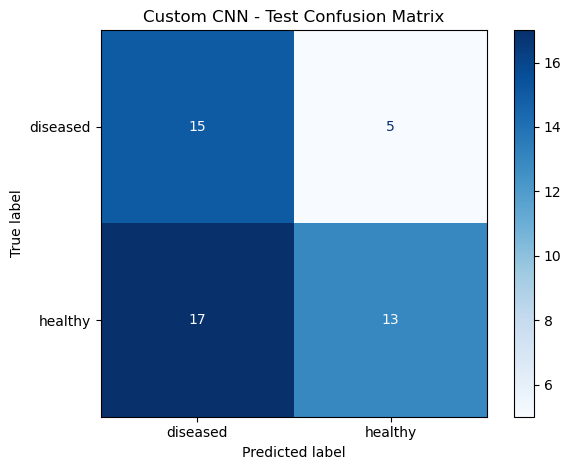

In [14]:
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_prob = best_model.predict(test_ds, verbose=1).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Custom CNN - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
import json

best_model.save(OUTPUT_DIR / "custom_cnn_final.keras")

with open(OUTPUT_DIR / "training_history.json", "w") as f:
    json.dump(
        {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        },
        f,
        indent=2
    )

print("Saved results to:", OUTPUT_DIR.resolve())